In [4]:
import pandas as pd

df = pd.read_csv("Datasets/mortgage_csv/mortgage.csv")
df.head()

,id,time,orig_time,first_time,mat_time,balance_time,LTV_time,interest_rate_time,hpi_time,gdp_time,...,REtype_SF_orig_time,investor_orig_time,balance_orig_time,FICO_orig_time,LTV_orig_time,Interest_Rate_orig_time,hpi_orig_time,default_time,payoff_time,status_time
0,1,25,-7,25,113,41303.42,24.498336,9.2,226.29,2.899137,...,1,0,45000.0,715,69.4,9.2,87.03,0,0,0
1,1,26,-7,25,113,41061.95,24.483867,9.2,225.10,2.151365,...,1,0,45000.0,715,69.4,9.2,87.03,0,0,0
2,1,27,-7,25,113,40804.42,24.626795,9.2,222.39,2.361722,...,1,0,45000.0,715,69.4,9.2,87.03,0,0,0
3,1,28,-7,25,113,40483.89,24.735883,9.2,219.67,1.229172,...,1,0,45000.0,715,69.4,9.2,87.03,0,0,0
4,1,29,-7,25,113,40367.06,24.925476,9.2,217.37,1.692969,...,1,0,45000.0,715,69.4,9.2,87.03,0,0,0


In [5]:
def proc_freq(df, col):
    freq = df[col].value_counts().sort_index().to_frame("Frequency")
    freq["Percent"] = (freq["Frequency"] / freq["Frequency"].sum() * 100).round(2)
    freq["Cumulative Frequency"] = freq["Frequency"].cumsum()
    freq["Cumulative Percent"] = freq["Percent"].cumsum()
    return freq.reset_index(names=col)

proc_freq(df, "default_time")


,default_time,Frequency,Percent,Cumulative Frequency,Cumulative Percent
0,0,607331,97.56,607331,97.56
1,1,15158,2.44,622489,100.00


<Axes: xlabel='FICO_orig_time', ylabel='Count'>

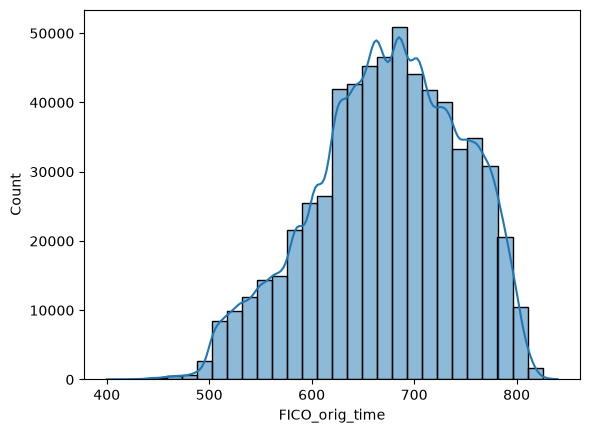

In [ ]:
import seaborn as sns
sns.histplot(df["FICO_orig_time"], kde=True, bins=30)


In [ ]:
import matplotlib.pyplot as plt
from statsmodels.nonparametric.kde import KDEUnivariate

data = df["FICO_orig_time"].dropna()

# Non-parametric KDE, Epanechnikov kernel, optimal (Silverman-type) bandwidth
kde = KDEUnivariate(data)
kde.fit(kernel="epa", bw="silverman", fft=False, gridsize=512)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(kde.support, kde.density, color="#2a78d6", linewidth=2)
ax.fill_between(kde.support, kde.density, color="#2a78d6", alpha=0.15)
ax.set_title(f"FICO_orig_time density (Epanechnikov kernel, optimal bw = {kde.bw:.3f})")
ax.set_xlabel("FICO_orig_time")
ax.set_ylabel("Density")
ax.spines[["top", "right"]].set_visible(False)
plt.show()


In [ ]:
def proc_freq_2d(df, row, col, bins=None, labels=None, normalize=False, margins=True):
    row_data = df[row]
    if bins is not None:
        row_data = pd.cut(row_data, bins=bins, labels=labels)
        row_data.name = row

    table = pd.crosstab(row_data, df[col], margins=margins, margins_name="Total", normalize=normalize)
    if normalize:
        table = (table * 100).round(2)
    return table


fico_bins = [300, 579, 669, 739, 799, 850]
fico_labels = ["Poor (<580)", "Fair (580-669)", "Good (670-739)", "Very Good (740-799)", "Exceptional (800+)"]

proc_freq_2d(df, "FICO_orig_time", "default_time", bins=fico_bins, labels=fico_labels)
